
# MOROCCO ELECTRICITY CONSUMPTION AND ENVIRONMENTAL FACTORS ANALYSIS

# 1. Business Understanding

## Project Background

An energy management organisation in Morocco wants to understand electricity consumption patterns across three geographical zones.

The organisation collects electricity consumption readings at 10-minute intervals alongside environmental measurements, including temperature, humidity, wind speed and diffuse-flow measurements.

The objective of this analysis is to transform historical consumption and environmental data into meaningful business intelligence that supports energy monitoring, demand planning and operational decision-making.

## Business Objectives

This analysis aims to:

1. Identify electricity consumption patterns across the three zones.
2. Determine the hours and days associated with the highest and lowest consumption.
3. Examine monthly consumption variations.
4. Investigate relationships between environmental conditions and electricity consumption.
5. Compare consumption levels across the three geographical zones.
6. Identify how historical consumption patterns can inform energy management and planning.

## Analytical Approach

The analysis will use descriptive statistics, time-based analysis, data visualisation and correlation analysis.

Findings will be interpreted in the context of energy management, with attention to data quality, measurement definitions and the limitations of observational data.

## Expected Business Value

The analysis is intended to help management:

- Understand demand patterns and peak periods.
- Identify differences in consumption across geographical zones.
- Monitor seasonal and environmental relationships.
- Support evidence-based energy planning.
- Identify areas requiring further operational investigation.

**Important:** Electricity consumption units and the meaning of environmental measurements will be verified before calculating energy totals or interpreting their physical significance.



# 2. Data Understanding and Inspection

## Objective

Understand the structure, scope and contents of the electricity consumption dataset before performing any cleaning or analysis.

The dataset contains electricity consumption readings recorded at 10-minute intervals across three geographical zones in Morocco, together with environmental measurements.

This section examines:

- Dataset dimensions and structure.
- Column names and data types.
- First and last recorded observations.
- Electricity consumption and environmental variables.
- Data dictionary definitions.
- Reporting period and expected observation frequency.

## Business Relevance

Understanding the dataset is necessary to establish what each observation represents, determine which variables can support the business questions and identify any measurement limitations.

Particular attention will be given to the definitions and units of the electricity consumption and diffuse-flow variables.


## Load the datasets

In [11]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project data directory
data_path = Path(
    r"C:\Users\User\Desktop\ANALYSTLAB AFRICA\05_Morocco_Electricity_Consumption_and_Environmental_Factors_Analysis\01_raw_data"
)

# Load electricity consumption dataset
df = pd.read_csv(data_path / "powerconsumption.csv")

# Load data dictionary
dictionary = pd.read_csv(
    data_path / "powerconsumption_datadictionary.csv"
)

# Display confirmation
print("Datasets loaded successfully.")
print("Main dataset:", df.shape)
print("Data dictionary:", dictionary.shape)


Datasets loaded successfully.
Main dataset: (52416, 9)
Data dictionary: (9, 2)


## Verify loading

In [12]:

display(df.head())
display(dictionary)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.56,73.80,0.08,0.05,0.12,"34,055.70","16,128.88","20,240.96"
1,1/1/2017 0:10,6.41,74.50,0.08,0.07,0.09,"29,814.68","19,375.08","20,131.08"
2,1/1/2017 0:20,6.31,74.50,0.08,0.06,0.10,"29,128.10","19,006.69","19,668.43"
3,1/1/2017 0:30,6.12,75.00,0.08,0.09,0.10,"28,228.86","18,361.09","18,899.28"
4,1/1/2017 0:40,5.92,75.70,0.08,0.05,0.09,"27,335.70","17,872.34","18,442.41"


,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


## Understanding the dataset fields

In [13]:
pd.set_option('display.max_colwidth', None)

display(dictionary.to_string(index=False))

'                 Field                                                                     Description\n              Datetime                                              The date and time of the recording\n           Temperature                                                      The Temperature in Celsius\n              Humidity                                     The concentration of water vapor in the air\n             WindSpeed                                    The speed of the wind in kilometers per hour\n   GeneralDiffuseFlows The measurement of how much emissions gases diffuse into the broader atmosphere\n          DiffuseFlows   The measurement of how much emissions gases diffuse into the local atmosphere\nPowerConsumption_Zone1                         The power consumption in Kilowatt-Hours in Power Zone 1\nPowerConsumption_Zone2                         The power consumption in Kilowatt-Hours in Power Zone 2\nPowerConsumption_Zone3                         The power consum

## Inspecting data types and reporting period

In [14]:
# Inspect column data types
print("DATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))

# Convert datetime field
df['Datetime'] = pd.to_datetime(
    df['Datetime'],
    errors='coerce'
)

# Reporting period
print("\nREPORTING PERIOD")
print("Start:", df['Datetime'].min())
print("End:", df['Datetime'].max())

# Number of unique dates
print("\nUnique dates:",
      df['Datetime'].dt.date.nunique())

# Missing datetime values
print("\nInvalid datetime records:",
      df['Datetime'].isna().sum())

DATA TYPES


,Data Type
Datetime,str
Temperature,float64
Humidity,float64
WindSpeed,float64
GeneralDiffuseFlows,float64
DiffuseFlows,float64
PowerConsumption_Zone1,float64
PowerConsumption_Zone2,float64
PowerConsumption_Zone3,float64



REPORTING PERIOD
Start: 2017-01-01 00:00:00
End: 2017-12-30 23:50:00

Unique dates: 364

Invalid datetime records: 0


## Verify the observation frequency

In [15]:
# Sort observations chronologically
df = df.sort_values('Datetime').reset_index(drop=True)

# Calculate time difference between consecutive records
df['Time_Interval'] = df['Datetime'].diff()

# Examine interval frequencies
interval_counts = (
    df['Time_Interval']
    .value_counts()
    .rename_axis('Time Interval')
    .reset_index(name='Number of Records')
)

display(interval_counts.head(10))

,Time Interval,Number of Records
0,0 days 00:10:00,52415


## Check missing values

In [21]:
# Original dataset columns, excluding derived fields
source_columns = [
    'Datetime',
    'Temperature',
    'Humidity',
    'WindSpeed',
    'GeneralDiffuseFlows',
    'DiffuseFlows',
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

missing_report = pd.DataFrame({
    'Missing Records': df[source_columns].isnull().sum(),
    'Missing Percentage': (
        df[source_columns].isnull().mean() * 100
    )
})

display(missing_report)

,Missing Records,Missing Percentage
Datetime,0,0.00
Temperature,0,0.00
Humidity,0,0.00
WindSpeed,0,0.00
GeneralDiffuseFlows,0,0.00
DiffuseFlows,0,0.00
PowerConsumption_Zone1,0,0.00
PowerConsumption_Zone2,0,0.00
PowerConsumption_Zone3,0,0.00


## Duplicate Records

In [22]:
duplicate_rows = df.duplicated(subset=source_columns).sum()

duplicate_timestamps = df['Datetime'].duplicated().sum()

print("Completely duplicated records:", duplicate_rows)
print("Repeated timestamps:", duplicate_timestamps)

Completely duplicated records: 0
Repeated timestamps: 0


## Daily observation completeness

In [23]:
daily_records = (
    df.groupby(df['Datetime'].dt.date)
    .size()
    .reset_index(name='Number of Readings')
)

incomplete_days = daily_records[
    daily_records['Number of Readings'] != 144
]

print("Recorded dates:", len(daily_records))
print("Expected readings per day: 144")
print("Incomplete or excess observation days:",
      len(incomplete_days))

display(incomplete_days)

Recorded dates: 364
Expected readings per day: 144
Incomplete or excess observation days: 0


,Datetime,Number of Readings


In [24]:
numeric_columns = [
    'Temperature',
    'Humidity',
    'WindSpeed',
    'GeneralDiffuseFlows',
    'DiffuseFlows',
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

negative_values = (df[numeric_columns] < 0).sum()

negative_report = pd.DataFrame({
    'Negative Records': negative_values
})

display(negative_report)

print("Numerical summary:")
display(df[numeric_columns].describe().T)

,Negative Records
Temperature,0
Humidity,0
WindSpeed,0
GeneralDiffuseFlows,0
DiffuseFlows,0
PowerConsumption_Zone1,0
PowerConsumption_Zone2,0
PowerConsumption_Zone3,0


Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Temperature,"52,416.00",18.81,5.82,3.25,14.41,18.78,22.89,40.01
Humidity,"52,416.00",68.26,15.55,11.34,58.31,69.86,81.40,94.80
WindSpeed,"52,416.00",1.96,2.35,0.05,0.08,0.09,4.92,6.48
GeneralDiffuseFlows,"52,416.00",182.70,264.40,0.00,0.06,5.04,319.60,"1,163.00"
DiffuseFlows,"52,416.00",75.03,124.21,0.01,0.12,4.46,101.00,936.00
PowerConsumption_Zone1,"52,416.00","32,344.97","7,130.56","13,895.70","26,310.67","32,265.92","37,309.02","52,204.40"
PowerConsumption_Zone2,"52,416.00","21,042.51","5,201.47","8,560.08","16,980.77","20,823.17","24,713.72","37,408.86"
PowerConsumption_Zone3,"52,416.00","17,835.41","6,622.17","5,935.17","13,129.33","16,415.12","21,624.10","47,598.33"


## Calender Coverage

In [25]:
expected_dates = pd.date_range(
    start=df['Datetime'].min().normalize(),
    end=df['Datetime'].max().normalize(),
    freq='D'
)

actual_dates = pd.DatetimeIndex(
    pd.to_datetime(daily_records.iloc[:, 0])
)

missing_dates = expected_dates.difference(actual_dates)

print("Expected calendar dates:", len(expected_dates))
print("Observed calendar dates:", len(actual_dates))
print("Missing calendar dates:", len(missing_dates))

display(missing_dates)

Expected calendar dates: 364
Observed calendar dates: 364
Missing calendar dates: 0


DatetimeIndex([], dtype='datetime64[us]', freq='D')

# Business Questions

## What patterns can be identified in electricity consumption across the three zones?

In [26]:

zone_columns = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

zone_summary = df[zone_columns].agg(
    ['mean', 'median', 'std', 'min', 'max']
).T

zone_summary['Range'] = zone_summary['max'] - zone_summary['min']
zone_summary['CV (%)'] = (
    zone_summary['std'] / zone_summary['mean']
) * 100

zone_summary.index = ['Zone 1', 'Zone 2', 'Zone 3']

display(zone_summary.round(2))


,mean,median,std,min,max,Range,CV (%)
Zone 1,"32,344.97","32,265.92","7,130.56","13,895.70","52,204.40","38,308.70",22.05
Zone 2,"21,042.51","20,823.17","5,201.47","8,560.08","37,408.86","28,848.78",24.72
Zone 3,"17,835.41","16,415.12","6,622.17","5,935.17","47,598.33","41,663.15",37.13


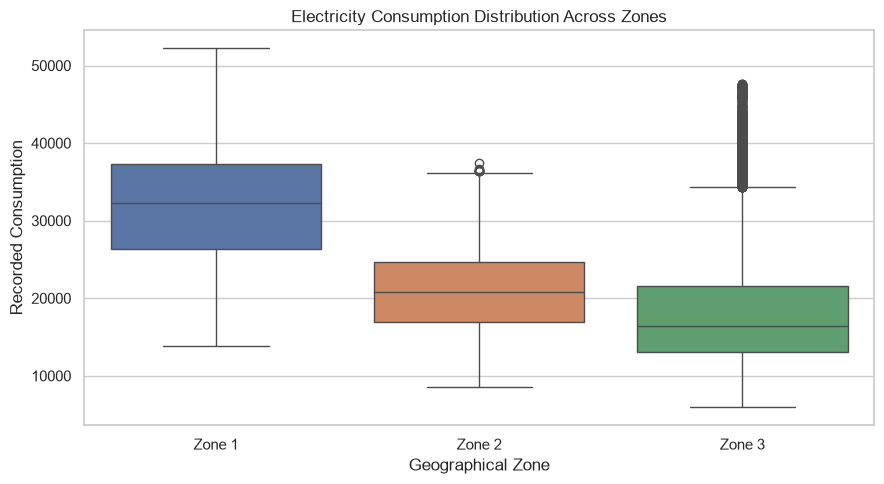

In [27]:

plt.figure(figsize=(9, 5))

sns.boxplot(data=df[zone_columns])

plt.title('Electricity Consumption Distribution Across Zones')
plt.xlabel('Geographical Zone')
plt.ylabel('Recorded Consumption')
plt.xticks([0, 1, 2], ['Zone 1', 'Zone 2', 'Zone 3'])
plt.tight_layout()
plt.show()



### Key Findings

- Zone 1 recorded the highest average consumption at 32,344.97.
- Zone 3 recorded the highest relative variability, with a coefficient of variation of 37.13%.
- Zone 1 had the lowest relative variability at 22.05%.
- Zone 3's mean exceeded its median, suggesting a distribution influenced by higher consumption readings.

**Business implication:** Energy management should monitor both consumption levels and demand variability across geographical zones to support more informed planning.


## During which hours and days does electricity consumption tend to be highest and lowest?

In [28]:

# Extract time components
df['Hour'] = df['Datetime'].dt.hour
df['Day'] = df['Datetime'].dt.day_name()

# Calculate average consumption by hour and day
hourly_consumption = df.groupby('Hour')[zone_columns].mean()
daily_consumption = df.groupby('Day')[zone_columns].mean()

print("Average consumption by hour:")
display(hourly_consumption.round(2))

print("Average consumption by day:")
display(daily_consumption.round(2))


Average consumption by hour:


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,"30,217.24","19,692.07","18,657.22"
1,"27,565.53","17,765.08","16,970.80"
2,"26,292.69","16,730.16","15,981.10"
3,"25,338.12","16,052.59","15,238.61"
4,"24,633.58","15,624.08","14,671.04"
5,"23,437.58","14,974.91","13,226.38"
6,"23,203.60","14,934.70","12,051.60"
7,"24,038.35","15,719.12","11,667.86"
8,"26,583.26","17,529.68","12,793.79"


Average consumption by day:


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day,,,
Friday,"32,339.00","21,461.04","17,545.97"
Monday,"32,615.41","21,280.07","17,809.08"
Saturday,"32,253.03","20,585.96","18,011.19"
Sunday,"30,780.08","18,979.38","17,954.83"
Thursday,"32,842.48","21,845.16","17,843.69"
Tuesday,"32,713.03","21,518.60","17,831.69"
Wednesday,"32,871.76","21,627.36","17,851.40"


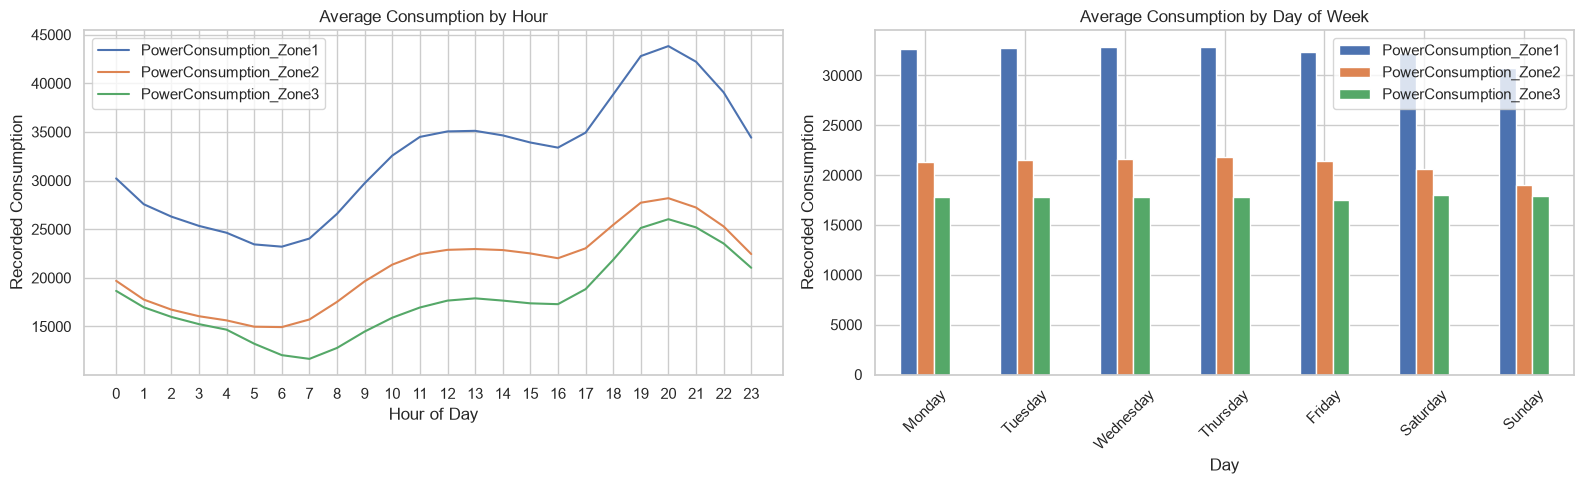

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

hourly_consumption.plot(ax=axes[0])
axes[0].set_title('Average Consumption by Hour')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Recorded Consumption')
axes[0].set_xticks(range(0, 24))

daily_consumption.reindex([
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]).plot(kind='bar', ax=axes[1])

axes[1].set_title('Average Consumption by Day of Week')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Recorded Consumption')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()



### Key Findings

- All three zones reach their highest hourly average consumption at 20:00.
- The lowest hourly average occurs at 07:00 across all zones.
- Zone 1 and Zone 2 record their highest daily averages on Wednesday, while Zone 3 peaks on Saturday.
- Sunday records the lowest daily averages in Zone 1 and Zone 2, while Zone 3 records its lowest on Friday.

**Business implication:** The evening peak provides a key period for demand monitoring and energy planning. Weekly consumption differences should also inform zone-specific planning.


## How does electricity consumption vary across months?

In [30]:

df['Month'] = df['Datetime'].dt.month

monthly_consumption = df.groupby('Month')[zone_columns].mean()

monthly_consumption.index = [
    pd.Timestamp(2017, month, 1).strftime('%B')
    for month in monthly_consumption.index
]

display(monthly_consumption.round(2))


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
January,"31,032.49","19,394.44","17,746.10"
February,"30,985.75","18,787.79","17,335.00"
March,"31,155.17","18,457.94","16,947.69"
April,"31,169.77","17,633.97","18,593.17"
May,"32,396.01","19,977.29","17,621.10"
June,"34,605.54","20,670.93","20,430.94"
July,"35,831.55","24,147.89","28,194.11"
August,"36,435.19","24,656.22","24,648.89"
September,"33,396.68","20,180.43","14,922.80"
October,"32,827.66","21,468.99","13,264.10"


<Figure size 1200x600 with 0 Axes>

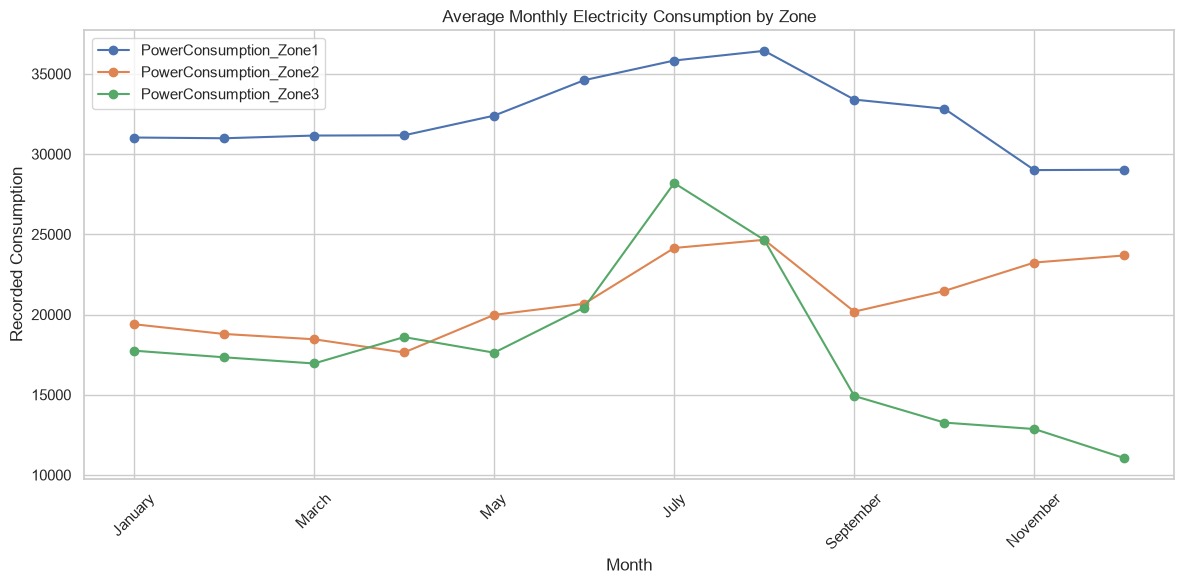

In [31]:

plt.figure(figsize=(12, 6))

monthly_consumption.plot(marker='o', figsize=(12, 6))

plt.title('Average Monthly Electricity Consumption by Zone')
plt.xlabel('Month')
plt.ylabel('Recorded Consumption')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()



### Key Findings

- Zone 1 and Zone 2 record their highest monthly average consumption in August.
- Zone 3 reaches its highest monthly average in July.
- Zone 1 records its lowest monthly average in November, Zone 2 in April and Zone 3 in December.
- Zone 3 shows the most pronounced mid-year increase and subsequent decline.

**Business implication:** Monthly demand planning should account for different consumption patterns across zones rather than applying a single seasonal assumption to all three.


## Are temperature, humidity and wind speed associated with electricity consumption?

In [32]:

environmental_columns = ['Temperature', 'Humidity', 'WindSpeed']

correlation_data = df[
    environmental_columns + zone_columns
]

correlation_matrix = correlation_data.corr()

display(
    correlation_matrix.loc[
        environmental_columns, zone_columns
    ].round(3)
)


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


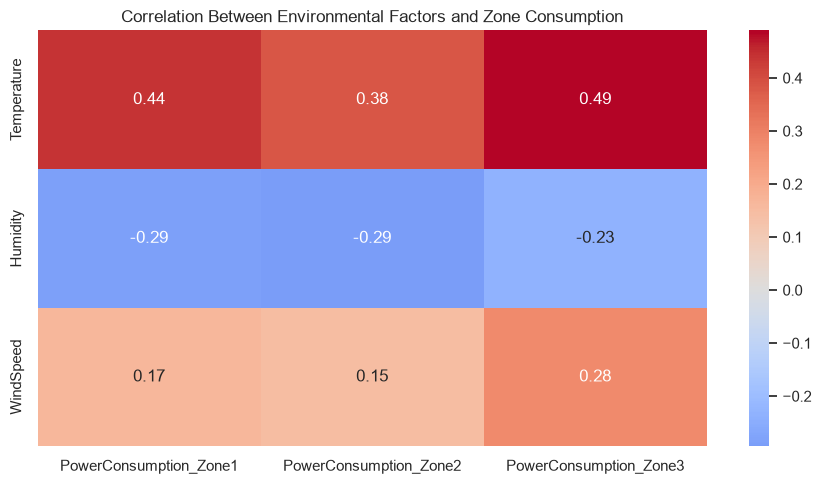

In [33]:

plt.figure(figsize=(9, 5))

sns.heatmap(
    correlation_matrix.loc[environmental_columns, zone_columns],
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f'
)

plt.title('Correlation Between Environmental Factors and Zone Consumption')
plt.tight_layout()
plt.show()



### Key Findings

- Temperature has a positive correlation with consumption across all zones, strongest in Zone 3 (0.49).
- Humidity has a negative correlation across all zones, ranging from -0.23 to -0.29.
- Wind speed has a weak positive correlation, strongest in Zone 3 (0.28).
- Temperature shows the strongest linear association with recorded electricity consumption among the environmental variables examined.

**Business implication:** Temperature deserves further investigation as a potential demand-planning variable. Correlation results alone cannot establish causation.


## Which zone records the highest and lowest consumption?

In [40]:

zone_ranking = (
    df[zone_columns]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

zone_ranking.columns = ['Zone', 'Average Consumption']

zone_ranking['Zone'] = (
    zone_ranking['Zone'].str.replace(
        'PowerConsumption_', '', regex=False
    )
)

# Assign ranking starting from 1
zone_ranking.insert(
    0, 'Rank', range(1, len(zone_ranking) + 1)
)

display(zone_ranking.round(2))


,Rank,Zone,Average Consumption
0,1,Zone1,"32,344.97"
1,2,Zone2,"21,042.51"
2,3,Zone3,"17,835.41"


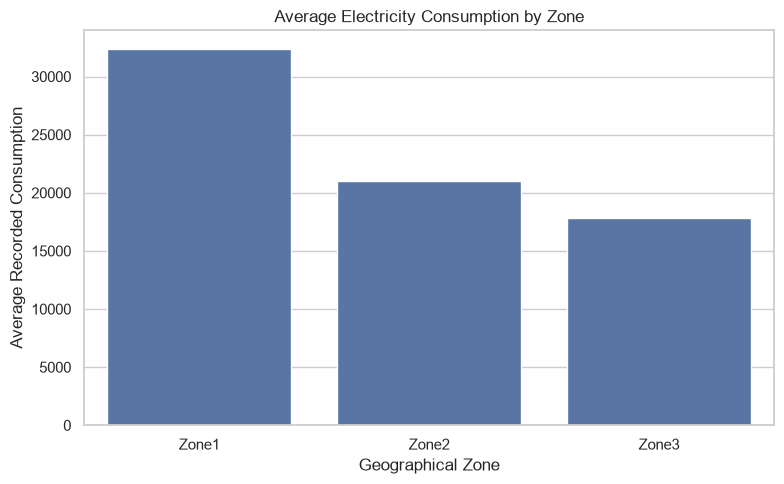


### Key Findings

- Zone 1 records the highest average consumption at 32,344.97.
- Zone 2 ranks second at 21,042.51.
- Zone 3 records the lowest average consumption at 17,835.41.
- Zone 1's average consumption is approximately 81.8% higher than Zone 3's.

**Business implication:** Prioritise Zone 1 for demand monitoring while maintaining attention on Zone 3 due to its greater relative consumption variability.


## Energy Planning and Management Recommendations

In [39]:

# Consolidate average consumption by zone
print("Average consumption by zone:")
display(df[zone_columns].mean().round(2))

print("Peak hourly consumption:")
display(hourly_consumption.idxmax())

print("Lowest hourly consumption:")
display(hourly_consumption.idxmin())

print("Peak monthly consumption:")
display(monthly_consumption.idxmax())

print("Lowest monthly consumption:")
display(monthly_consumption.idxmin())


Average consumption by zone:


PowerConsumption_Zone1   32,344.97
PowerConsumption_Zone2   21,042.51
PowerConsumption_Zone3   17,835.41
dtype: float64

Peak hourly consumption:


PowerConsumption_Zone1    20
PowerConsumption_Zone2    20
PowerConsumption_Zone3    20
dtype: int32

Lowest hourly consumption:


PowerConsumption_Zone1    6
PowerConsumption_Zone2    6
PowerConsumption_Zone3    7
dtype: int32

Peak monthly consumption:


PowerConsumption_Zone1    August
PowerConsumption_Zone2    August
PowerConsumption_Zone3      July
dtype: str

Lowest monthly consumption:


PowerConsumption_Zone1    November
PowerConsumption_Zone2       April
PowerConsumption_Zone3    December
dtype: str


### Management Recommendations

Based on the analysis, the following actions are recommended:

1. **Peak demand management:** Monitor evening consumption, particularly around 18:00–21:00, when all three zones experience their highest average demand.

2. **Zone-specific planning:** Give Zone 1 priority in demand monitoring due to its highest average consumption, while monitoring Zone 3 for its greater relative variability.

3. **Seasonal demand planning:** Incorporate monthly consumption patterns into energy forecasts, with particular attention to the July–August demand increases.

4. **Environmental monitoring:** Investigate temperature alongside electricity demand when developing forecasting models, as it has the strongest observed correlation among the environmental variables examined.

5. **Continuous monitoring:** Establish regular zone-level reporting to track demand changes, identify unusual consumption patterns and support operational decisions.

### Conclusion

The analysis demonstrates differences in electricity consumption across the three geographical zones, with identifiable hourly, weekly and monthly patterns.

These findings provide an evidence-based starting point for demand monitoring, seasonal planning and zone-specific energy management.


In [41]:

# Create additional time-based features
df['Year'] = df['Datetime'].dt.year
df['Date'] = df['Datetime'].dt.date

# Confirm all time-based features
display(
    df[['Datetime', 'Year', 'Month', 'Date', 'Day', 'Hour']].head()
)


,Datetime,Year,Month,Date,Day,Hour
0,2017-01-01 00:00:00,2017,1,2017-01-01,Sunday,0
1,2017-01-01 00:10:00,2017,1,2017-01-01,Sunday,0
2,2017-01-01 00:20:00,2017,1,2017-01-01,Sunday,0
3,2017-01-01 00:30:00,2017,1,2017-01-01,Sunday,0
4,2017-01-01 00:40:00,2017,1,2017-01-01,Sunday,0


In [43]:
%pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 1.7 MB/s eta 0:00:06
   ------- -------------------------------- 1.8/9.7 MB 3.0 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.7 MB 3.9 MB/s eta 0:00:02
   ------------ --------------------------- 3.1/9.7 MB 3.2 MB/s eta 0:00:03
   ------------ --------------------------- 3.1/9.7 MB 3.2 MB/s eta 0:00:03
   ------------ --------------------------- 3.1/9.7 MB 3.2 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.7 MB 2.2 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.7 MB 1.9 MB/s eta 0:00:04
   --------------- ------------------------ 3.7/9.7 MB 1.9 MB/s eta 0:00:04
   --------------- ---------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [46]:
import plotly.express as px
import plotly.graph_objects as go

print("Plotly installed successfully")

Plotly installed successfully



### Daily and Weekly Electricity Consumption Patterns

Examine how average electricity consumption changes across individual dates and calendar weeks.

This analysis helps identify demand fluctuations over time and recurring weekly patterns across the three geographical zones.


### Aggregate daily and weekly consumption

In [47]:

# Daily average consumption
daily_consumption = (
    df.groupby('Date')[zone_columns]
    .mean()
    .reset_index()
)

# Weekly average consumption
df['Week'] = df['Datetime'].dt.isocalendar().week

weekly_consumption = (
    df.groupby('Week')[zone_columns]
    .mean()
    .reset_index()
)

display(daily_consumption.head())
display(weekly_consumption.head())


,Date,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01,"28,465.23","17,737.79","17,868.80"
1,2017-01-02,"28,869.49","19,557.73","17,820.76"
2,2017-01-03,"30,562.45","20,057.27","17,620.80"
3,2017-01-04,"30,689.83","20,102.08","17,673.69"
4,2017-01-05,"30,802.91","20,033.94","17,664.18"


,Week,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1,"30,258.51","19,480.62","17,722.44"
1,2,"30,659.93","19,285.63","17,435.14"
2,3,"31,721.78","19,775.79","18,000.18"
3,4,"31,706.08","19,369.09","17,830.84"
4,5,"30,862.25","18,463.07","17,560.19"


### Interactive weekly consumption chart

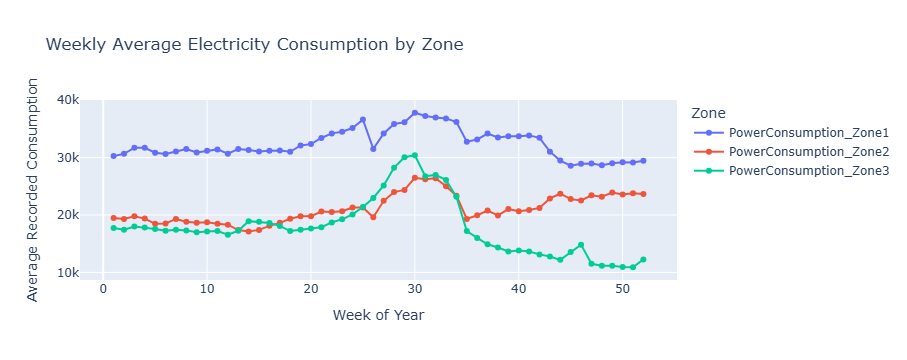

In [48]:

weekly_long = weekly_consumption.melt(
    id_vars='Week',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

fig = px.line(
    weekly_long,
    x='Week',
    y='Average Consumption',
    color='Zone',
    markers=True,
    title='Weekly Average Electricity Consumption by Zone',
    labels={
        'Week': 'Week of Year',
        'Average Consumption': 'Average Recorded Consumption'
    }
)

fig.show()


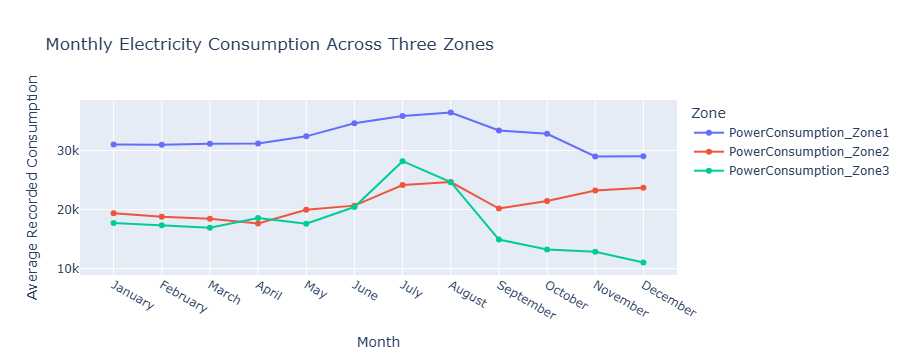

In [49]:

monthly_long = monthly_consumption.reset_index().melt(
    id_vars='index',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

monthly_long.rename(columns={'index': 'Month'}, inplace=True)

fig = px.line(
    monthly_long,
    x='Month',
    y='Average Consumption',
    color='Zone',
    markers=True,
    title='Monthly Electricity Consumption Across Three Zones',
    hover_data={'Average Consumption': ':.2f'}
)

fig.update_layout(
    xaxis_title='Month',
    yaxis_title='Average Recorded Consumption',
    hovermode='x unified'
)

fig.show()


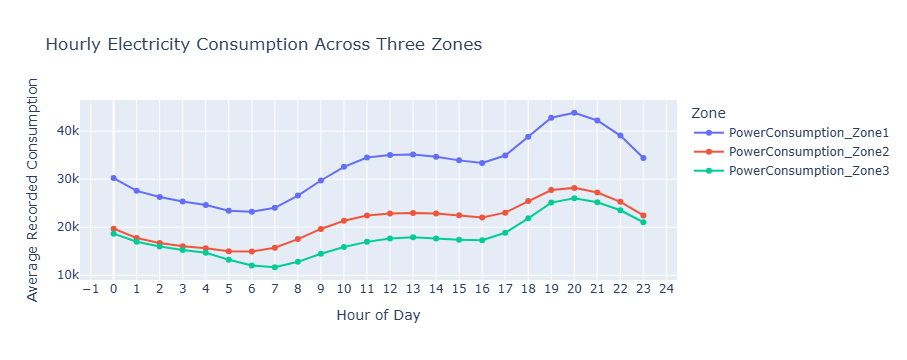

In [50]:

hourly_long = hourly_consumption.reset_index().melt(
    id_vars='Hour',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

fig = px.line(
    hourly_long,
    x='Hour',
    y='Average Consumption',
    color='Zone',
    markers=True,
    title='Hourly Electricity Consumption Across Three Zones'
)

fig.update_layout(
    xaxis_title='Hour of Day',
    yaxis_title='Average Recorded Consumption',
    xaxis=dict(tickmode='linear', dtick=1),
    hovermode='x unified'
)

fig.show()


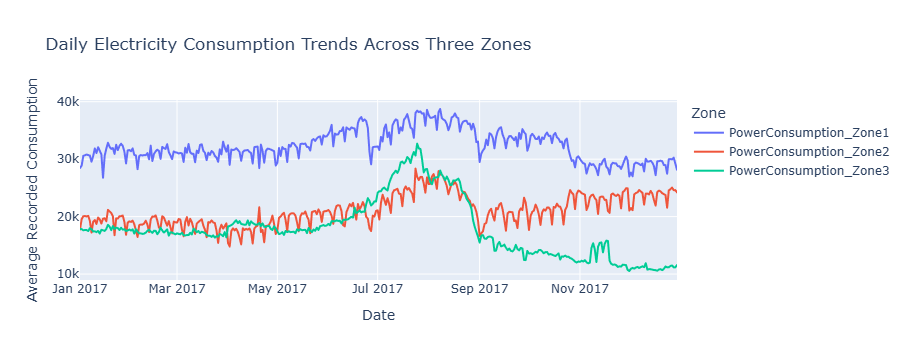

In [51]:

daily_long = daily_consumption.melt(
    id_vars='Date',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

fig = px.line(
    daily_long,
    x='Date',
    y='Average Consumption',
    color='Zone',
    title='Daily Electricity Consumption Trends Across Three Zones'
)

fig.update_layout(
    xaxis_title='Date',
    yaxis_title='Average Recorded Consumption',
    hovermode='x unified'
)

fig.show()


In [52]:

# 1. Overall zone performance
overall_summary = df[zone_columns].agg(
    ['mean', 'median', 'std', 'min', 'max']
).T

overall_summary['Range'] = (
    overall_summary['max'] - overall_summary['min']
)

overall_summary['CV (%)'] = (
    overall_summary['std'] / overall_summary['mean']
) * 100


# 2. Hourly consumption
hourly_summary = df.groupby('Hour')[zone_columns].agg(
    ['mean', 'min', 'max', 'std']
)


# 3. Daily consumption
daily_summary = df.groupby('Date')[zone_columns].mean()


# 4. Weekly consumption
weekly_summary = df.groupby('Week')[zone_columns].agg(
    ['mean', 'min', 'max', 'std']
)


# 5. Monthly consumption
monthly_summary = df.groupby('Month')[zone_columns].agg(
    ['mean', 'min', 'max', 'std']
)


# 6. Day-of-week consumption
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_summary = (
    df.groupby('Day')[zone_columns]
    .mean()
    .reindex(weekday_order)
)


# 7. Environmental correlation
environmental_summary = df[
    ['Temperature', 'Humidity', 'WindSpeed'] + zone_columns
].corr().loc[
    ['Temperature', 'Humidity', 'WindSpeed'],
    zone_columns
]


print("Analytical datasets prepared successfully.")
print("Overall summary:", overall_summary.shape)
print("Hourly summary:", hourly_summary.shape)
print("Daily summary:", daily_summary.shape)
print("Weekly summary:", weekly_summary.shape)
print("Monthly summary:", monthly_summary.shape)
print("Weekday summary:", weekday_summary.shape)
print("Environmental summary:", environmental_summary.shape)


Analytical datasets prepared successfully.
Overall summary: (3, 7)
Hourly summary: (24, 12)
Daily summary: (364, 3)
Weekly summary: (52, 12)
Monthly summary: (12, 12)
Weekday summary: (7, 3)
Environmental summary: (3, 3)


In [53]:

display(overall_summary.round(2))
display(hourly_summary.round(2))
display(weekly_summary.round(2))
display(monthly_summary.round(2))
display(weekday_summary.round(2))
display(environmental_summary.round(3))


,mean,median,std,min,max,Range,CV (%)
PowerConsumption_Zone1,"32,344.97","32,265.92","7,130.56","13,895.70","52,204.40","38,308.70",22.05
PowerConsumption_Zone2,"21,042.51","20,823.17","5,201.47","8,560.08","37,408.86","28,848.78",24.72
PowerConsumption_Zone3,"17,835.41","16,415.12","6,622.17","5,935.17","47,598.33","41,663.15",37.13


PowerConsumption_Zone1                               \
                       mean       min       max      std   
Hour                                                       
0                 30,217.24 21,192.91 45,558.68 4,530.07   
1                 27,565.53 18,161.01 44,503.31 4,586.72   
2                 26,292.69 16,727.09 44,859.34 5,011.50   
3                 25,338.12 16,107.34 40,409.01 3,996.48   
4                 24,633.58 15,663.80 32,220.40 2,927.81   
5                 23,437.58 15,846.08 28,787.21 2,002.03   
6                 23,203.60 16,398.99 28,113.09 1,881.38   
7                 24,038.35 13,895.70 31,759.91 2,687.71   
8                 26,583.26 14,327.09 35,902.51 3,250.58   
9                 29,725.36 17,024.81 39,591.21 3,406.73   
10                32,566.46 20,974.18 42,474.41 3,434.23   
11                34,487.63 24,212.66 43,919.20 3,434.61   
12                35,052.52 16,814.98 44,213.27 3,406.06   
13                35,112.27 26,412.92 44,098.20 3,282.76   
14                34,643.60 25,544.62 43,598.67 3,294.29   
15                33,912.00 25,292.31 42,960.27 3,283.99   
16                33,385.20 25,334.08 41,425.97 3,085.33   
17                34,924.98 25,259.68 45,040.18 3,243.09   
18                38,846.13 26,140.11 48,118.94 4,012.83   
19                42,795.92 27,388.61 51,820.82 3,510.00   
20                43,822.59 35,023.57 52,204.40 3,543.75   
21                42,216.48 33,593.92 50,778.78 3,790.12   
22                39,068.64 29,247.44 48,701.66 4,235.92   
23                34,409.58 24,645.45 48,254.30 4,639.96   

     PowerConsumption_Zone2                               \
                       mean       min       max      std   
Hour                                                       
0                 19,692.07 12,332.38 28,484.48 3,293.61   
1                 17,765.08 11,225.25 25,813.72 3,185.15   
2                 16,730.16 10,891.65 25,929.73 3,230.00   
3                 16,052.59 10,624.03 24,159.67 2,695.46   
4                 15,624.08 10,671.69 22,261.46 2,216.16   
5                 14,974.91  9,365.94 20,688.80 2,062.74   
6                 14,934.70  8,560.08 20,942.74 2,237.89   
7                 15,719.12  8,912.02 22,653.01 2,564.49   
8                 17,529.68  9,603.65 26,317.63 2,971.79   
9                 19,640.72 11,039.50 31,120.25 3,202.67   
10                21,356.67 12,345.53 32,734.18 3,268.48   
11                22,442.54 13,887.32 33,979.75 3,341.76   
12                22,876.88 14,421.88 34,294.94 3,277.25   
13                22,958.49 14,990.88 34,689.87 3,311.72   
14                22,855.35 14,968.23 34,929.11 3,307.16   
15                22,508.40 14,663.95 34,158.23 3,232.84   
16                22,014.48 14,173.17 33,098.73 3,228.16   
17                23,032.42 13,935.37 35,631.82 4,550.66   
18                25,443.90 14,436.66 35,323.14 4,715.59   
19                27,723.74 15,964.24 37,408.86 3,596.32   
20                28,186.91 19,404.07 36,482.79 3,470.42   
21                27,228.71 18,674.54 35,311.93 3,259.64   
22                25,284.94 16,731.57 33,852.16 3,257.77   
23                22,443.67 14,356.01 32,042.66 3,386.25   

     PowerConsumption_Zone3                               
                       mean       min       max      std  
Hour                                                      
0                 18,657.22 10,084.03 36,801.34 6,005.31  
1                 16,970.80  9,306.12 32,830.79 5,390.12  
2                 15,981.10  8,816.33 29,095.38 4,955.86  
3                 15,238.61  8,666.51 27,251.55 4,292.36  
4                 14,671.04  8,591.60 26,504.44 3,616.70  
5                 13,226.38  6,707.25 23,853.39 2,547.70  
6                 12,051.60  7,066.99 21,913.31 2,747.46  
7                 11,667.86  5,935.17 24,570.38 3,433.14  
8                 12,793.79  6,275.15 27,817.91 4,175.02  
9                 14,478.27  7,001.20 30,450.88 4,680.4

PowerConsumption_Zone1                               \
                       mean       min       max      std   
Week                                                       
1                 30,258.51 19,430.89 43,831.90 7,044.58   
2                 30,659.93 13,895.70 44,646.08 7,622.04   
3                 31,721.78 18,890.13 46,092.15 7,554.52   
4                 31,706.08 19,224.30 46,055.70 7,366.25   
5                 30,862.25 18,128.14 44,225.08 6,883.43   
6                 30,620.32 18,726.10 44,054.24 6,831.53   
7                 31,062.87 18,835.93 44,731.53 6,720.63   
8                 31,481.36 19,555.93 44,975.59 7,095.12   
9                 30,895.07 19,314.38 44,793.19 6,770.99   
10                31,181.98 19,142.81 46,803.06 6,661.25   
11                31,431.00 18,738.38 44,829.96 6,946.09   
12                30,691.17 18,003.06 45,038.30 6,893.67   
13                31,482.94 19,270.27 47,808.00 6,554.65   
14                31,344.99 19,803.49 45,373.18 6,317.30   
15                31,067.51 19,146.26 44,058.73 6,299.16   
16                31,173.06 16,814.98 46,204.00 6,737.15   
17                31,222.94 18,365.04 46,824.03 6,544.42   
18                31,005.73 17,689.18 45,803.02 6,667.79   
19                32,108.73 19,011.15 46,356.98 6,583.85   
20                32,349.06 20,937.44 46,923.54 6,393.66   
21                33,421.51 19,892.46 48,157.38 7,224.77   
22                34,221.09 21,012.98 48,737.48 7,133.99   
23                34,499.92 21,336.16 47,567.68 7,145.74   
24                35,152.57 20,700.40 47,567.68 7,199.79   
25                36,620.11 22,404.24 49,360.53 7,489.89   
26                31,517.13 19,467.02 45,359.20 6,324.23   
27                34,202.39 21,024.32 47,834.15 6,739.19   
28                35,866.41 20,730.90 49,862.59 6,585.60   
29                36,167.00 22,140.60 51,144.72 6,954.95   
30                37,816.15 24,277.48 51,540.20 6,916.82   
31                37,237.04 23,487.50 50,785.17 6,736.93   
32                36,973.58 22,554.14 52,204.40 7,094.65   
33                36,826.12 22,861.00 51,820.82 7,085.82   
34                36,199.30 23,225.39 50,113.92 6,965.95   
35                32,770.02 18,283.68 48,912.05 6,951.00   
36                33,164.91 21,249.56 46,946.55 6,430.76   
37                34,198.64 21,128.50 48,380.18 6,497.44   
38                33,508.12 21,364.25 47,666.55 6,581.67   
39                33,739.05 21,659.87 48,329.20 6,447.45   
40                33,730.65 22,176.63 47,598.77 6,434.23   
41                33,870.50 22,554.75 47,661.79 6,411.17   
42                33,442.24 21,414.09 47,176.54 6,522.42   
43                31,036.89 19,605.43 46,823.63 6,181.12   
44                29,483.86 18,603.08 41,782.06 5,856.06   
45                28,592.53 18,400.00 40,393.85 5,825.69   
46                28,924.71 18,590.77 39,760.00 5,822.66   
47                28,968.33 17,483.08 42,566.15 6,001.41   
48                28,673.49 17,624.33 41,575.38 6,063.50   
49                29,011.15 18,196.20 40,249.43 6,115.28   
50                29,188.54 18,196.20 40,748.29 6,132.66   
51                29,151.66 18,336.12 41,101.14 6,248.22   
52                29,435.56 18,045.57 43,972.62 6,402.07   

     PowerConsumption_Zone2                               \
                       mean       min       max      std   
Week                                                       
1                 19,480.62 11,438.30 27,698.48 4,452.37   
2                 19,285.63 12,204.26 27,133.13 4,164.19   
3                 19,775.79  9,457.75 29,770.21 4,987.71   
4                 19,369.09 10,468.09 27,621.88 4,499.95   
5                 18,463.07 10,617.63 26,239.51 4,140.82   
6                 18,534.95  9,997.57 26,217.63 4,204.53   
7                 19,312.64 10,851.06 29,719.15 4,562.02   
8                 18,836.45 10,227.36 28,818.24 4,640.82   
9                 18,633.98 10,031.71 26,531

PowerConsumption_Zone1                               \
                        mean       min       max      std   
Month                                                       
1                  31,032.49 13,895.70 46,092.15 7,400.28   
2                  30,985.75 18,128.14 44,975.59 6,869.04   
3                  31,155.17 18,003.06 47,808.00 6,777.75   
4                  31,169.77 16,814.98 46,824.03 6,485.66   
5                  32,396.01 17,689.18 48,157.38 6,801.74   
6                  34,605.54 19,467.02 49,360.53 7,317.12   
7                  35,831.55 20,303.52 51,540.20 6,977.98   
8                  36,435.19 18,283.68 52,204.40 7,061.59   
9                  33,396.68 20,172.74 48,380.18 6,502.96   
10                 32,827.66 19,605.43 47,661.79 6,491.56   
11                 29,002.11 17,483.08 42,566.15 5,902.68   
12                 29,024.17 17,624.33 43,972.62 6,176.40   

      PowerConsumption_Zone2                               \
                        mean       min       max      std   
Month                                                       
1                  19,394.44  9,457.75 29,770.21 4,522.18   
2                  18,787.79  9,997.57 29,719.15 4,391.32   
3                  18,457.94  9,695.12 29,056.10 4,181.24   
4                  17,633.97  8,560.08 30,940.94 3,833.90   
5                  19,977.29  9,365.94 29,502.17 4,179.12   
6                  20,670.93  9,972.97 30,109.77 4,457.49   
7                  24,147.89 12,497.47 37,408.86 4,966.46   
8                  24,656.22 11,674.34 36,482.79 5,157.58   
9                  20,180.43 10,624.12 32,545.95 4,221.33   
10                 21,468.99 11,158.51 34,861.00 4,615.93   
11                 23,240.46 12,138.84 35,631.82 5,432.05   
12                 23,681.85 12,368.21 35,138.39 5,711.79   

      PowerConsumption_Zone3                               
                        mean       min       max      std  
Month                                                      
1                  17,746.10 10,039.52 27,724.34 4,433.85  
2                  17,335.00  9,592.28 28,145.85 4,359.98  
3                  16,947.69  9,348.39 27,720.00 4,251.36  
4                  18,593.17 10,065.45 29,666.91 4,544.81  
5                  17,621.10  9,840.97 28,030.45 4,357.84  
6                  20,430.94 10,379.82 33,756.55 5,606.91  
7                  28,194.11 13,562.51 47,598.33 6,933.66  
8                  24,648.89  9,961.13 41,415.42 6,499.41  
9                  14,922.80  6,707.25 25,575.81 3,438.64  
10                 13,264.10  7,446.57 20,734.83 3,092.95  
11                 12,862.50  6,511.81 25,972.05 3,510.03  
12                 11,044.81  5,935.17 17,505.88 2,853.39

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day,,,
Monday,"32,615.41","21,280.07","17,809.08"
Tuesday,"32,713.03","21,518.60","17,831.69"
Wednesday,"32,871.76","21,627.36","17,851.40"
Thursday,"32,842.48","21,845.16","17,843.69"
Friday,"32,339.00","21,461.04","17,545.97"
Saturday,"32,253.03","20,585.96","18,011.19"
Sunday,"30,780.08","18,979.38","17,954.83"


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


In [54]:
# 1. Peak and lowest hourly averages by zone
peak_hour_summary = hourly_summary.xs('mean', axis=1, level=1).agg(['idxmax', 'max', 'idxmin', 'min']).T

# 2. Zone comparison and average consumption contribution
zone_comparison = overall_summary[['mean', 'std', 'CV (%)']].copy()

zone_comparison['Share of Combined Zone Mean (%)'] = (
    zone_comparison['mean'] / zone_comparison['mean'].sum()
) * 100

zone_comparison['Difference from Highest Zone (%)'] = (
    (zone_comparison['mean'].max() - zone_comparison['mean'])
    / zone_comparison['mean'].max()
) * 100

display(peak_hour_summary.round(2))
display(zone_comparison.round(2))

,idxmax,max,idxmin,min
PowerConsumption_Zone1,20.00,"43,822.59",6.00,"23,203.60"
PowerConsumption_Zone2,20.00,"28,186.91",6.00,"14,934.70"
PowerConsumption_Zone3,20.00,"26,027.61",7.00,"11,667.86"


,mean,std,CV (%),Share of Combined Zone Mean (%),Difference from Highest Zone (%)
PowerConsumption_Zone1,"32,344.97","7,130.56",22.05,45.41,0.00
PowerConsumption_Zone2,"21,042.51","5,201.47",24.72,29.54,34.94
PowerConsumption_Zone3,"17,835.41","6,622.17",37.13,25.04,44.86



### 4. Environmental Relationship Analysis

Investigate the statistical relationships between temperature, humidity, wind speed and electricity consumption across the three zones.

The analysis uses:
- Descriptive statistics to understand environmental conditions.
- Pearson and Spearman correlation coefficients to assess associations.
- Environmental range profiles to compare average consumption under different conditions.

Correlation results will be interpreted as statistical associations, not proof of causation.


In [55]:

# Environmental variables
environmental_variables = ['Temperature', 'Humidity', 'WindSpeed']

# Descriptive statistics
environmental_statistics = df[environmental_variables].agg(
    ['mean', 'median', 'std', 'min', 'max']
).T

# Pearson correlation
pearson_results = df[
    environmental_variables + zone_columns
].corr(method='pearson').loc[environmental_variables, zone_columns]

# Spearman correlation
spearman_results = df[
    environmental_variables + zone_columns
].corr(method='spearman').loc[environmental_variables, zone_columns]

print("Environmental Descriptive Statistics")
display(environmental_statistics.round(2))

print("Pearson Correlation")
display(pearson_results.round(3))

print("Spearman Correlation")
display(spearman_results.round(3))


Environmental Descriptive Statistics


,mean,median,std,min,max
Temperature,18.81,18.78,5.82,3.25,40.01
Humidity,68.26,69.86,15.55,11.34,94.80
WindSpeed,1.96,0.09,2.35,0.05,6.48


Pearson Correlation


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


Spearman Correlation


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.43,0.38,0.44
Humidity,-0.30,-0.31,-0.21
WindSpeed,0.11,0.09,0.08


In [56]:

profile_frames = []

for factor in environmental_variables:
    temp = df[[factor] + zone_columns].copy()

    temp['Factor Range'] = pd.qcut(
        temp[factor],
        q=5,
        duplicates='drop'
    )

    profile = (
        temp.groupby('Factor Range', observed=True)[zone_columns]
        .mean()
        .reset_index()
    )

    profile.insert(0, 'Environmental Factor', factor)
    profile_frames.append(profile)

environmental_profiles = pd.concat(
    profile_frames,
    ignore_index=True
)

display(environmental_profiles.round(2))


,Environmental Factor,Factor Range,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,Temperature,"(3.246, 13.62]","28,286.94","18,708.73","14,963.32"
1,Temperature,"(13.62, 16.76]","30,802.59","20,055.03","16,082.80"
2,Temperature,"(16.76, 20.43]","31,652.86","20,667.37","15,828.13"
3,Temperature,"(20.43, 23.97]","34,044.24","21,567.72","18,047.92"
4,Temperature,"(23.97, 40.01]","36,956.56","24,225.47","24,274.40"
5,Humidity,"(11.339, 55.13]","35,151.59","23,071.01","20,220.20"
6,Humidity,"(55.13, 65.65]","33,319.54","21,774.69","18,001.39"
7,Humidity,"(65.65, 74.3]","32,461.22","21,305.08","17,448.16"
8,Humidity,"(74.3, 83.6]","31,862.96","20,596.44","17,563.43"
9,Humidity,"(83.6, 94.8]","28,886.28","18,432.69","15,922.07"


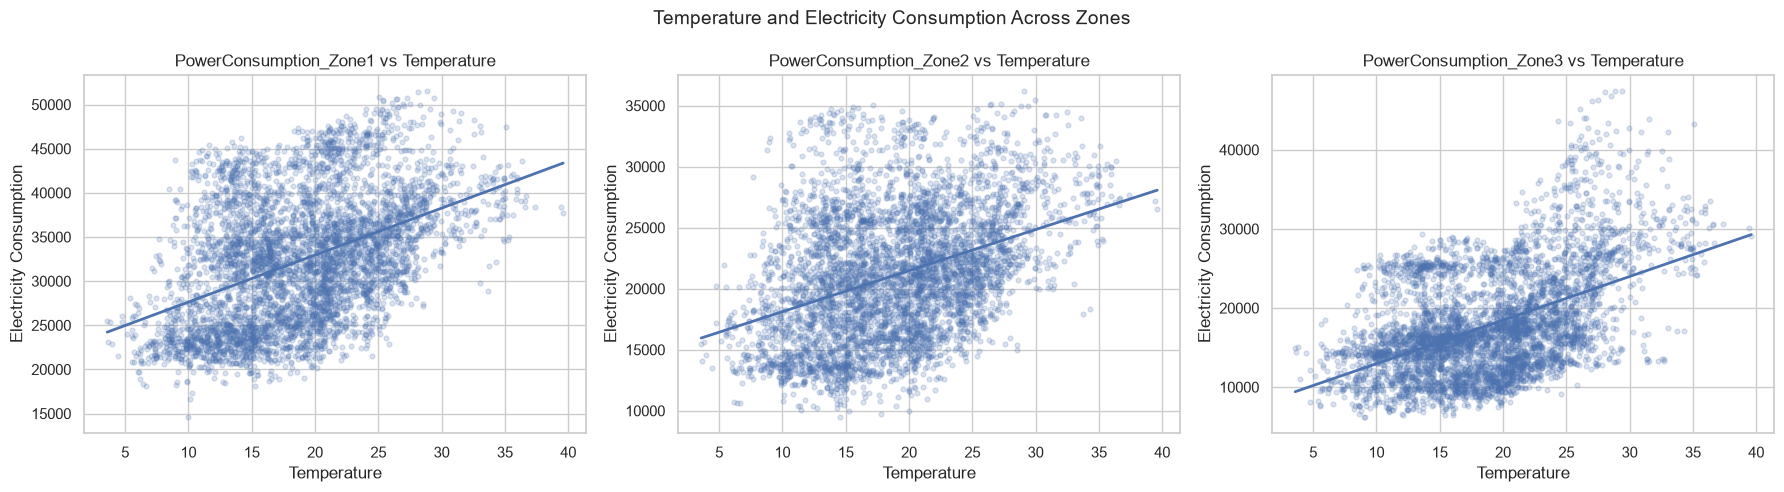

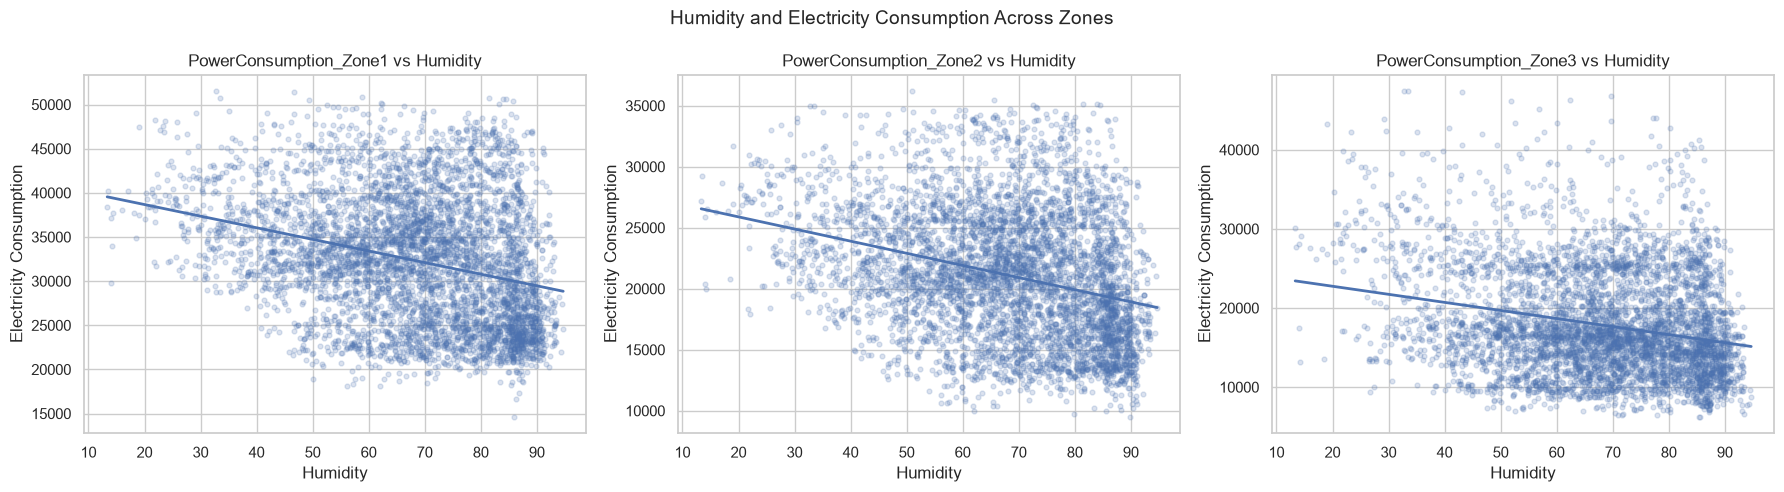

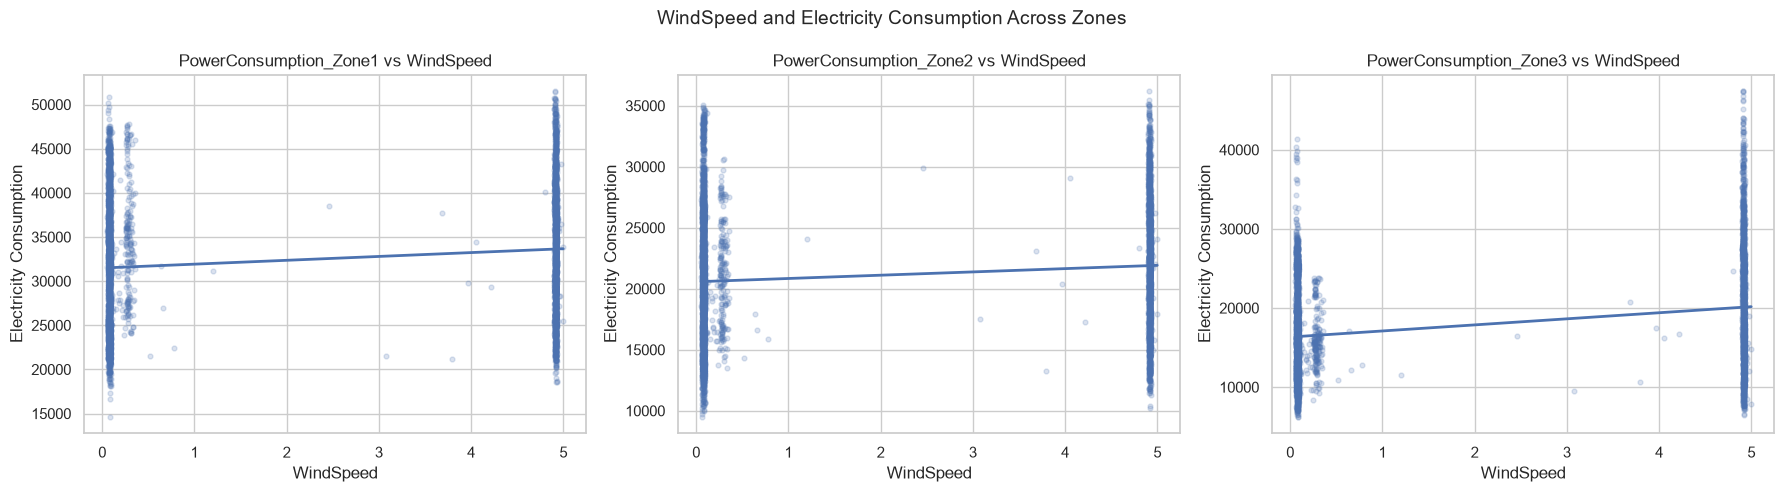

In [58]:

# Sample observations for clearer visualisation
plot_data = df.sample(
    n=5000,
    random_state=42
)

environmental_variables = ['Temperature', 'Humidity', 'WindSpeed']

for factor in environmental_variables:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, zone in zip(axes, zone_columns):
        sns.regplot(
            data=plot_data,
            x=factor,
            y=zone,
            ax=ax,
            scatter_kws={'alpha': 0.2, 's': 12},
            line_kws={'linewidth': 2},
            ci=None
        )

        ax.set_title(f'{zone} vs {factor}')
        ax.set_xlabel(factor)
        ax.set_ylabel('Electricity Consumption')

    fig.suptitle(
        f'{factor} and Electricity Consumption Across Zones',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


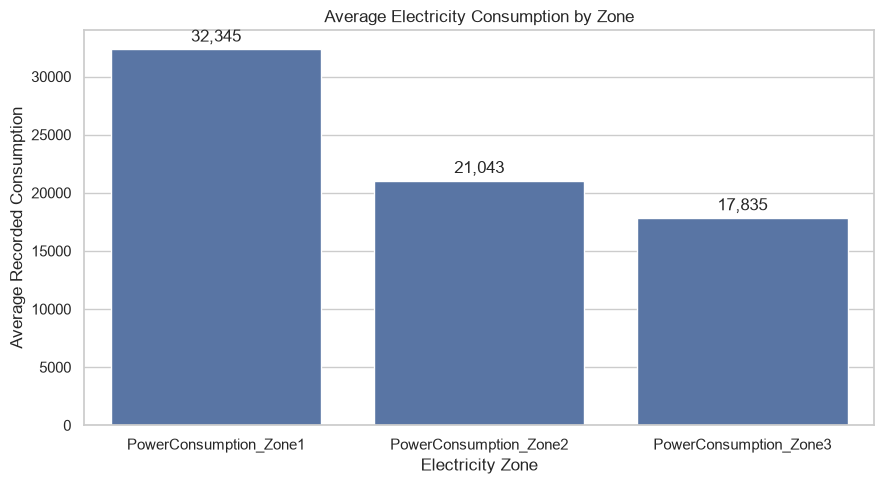

In [59]:

zone_means = (
    overall_summary['mean']
    .rename_axis('Zone')
    .reset_index(name='Average Consumption')
    .sort_values('Average Consumption', ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=zone_means,
    x='Zone',
    y='Average Consumption'
)

ax.set_title('Average Electricity Consumption by Zone')
ax.set_xlabel('Electricity Zone')
ax.set_ylabel('Average Recorded Consumption')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()
plt.show()


In [60]:

daily_trend = (
    df.groupby('Date')[zone_columns]
    .mean()
    .reset_index()
)

daily_trend['Date'] = pd.to_datetime(daily_trend['Date'])

display(daily_trend.head())
print("Daily observations:", len(daily_trend))


,Date,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01,"28,465.23","17,737.79","17,868.80"
1,2017-01-02,"28,869.49","19,557.73","17,820.76"
2,2017-01-03,"30,562.45","20,057.27","17,620.80"
3,2017-01-04,"30,689.83","20,102.08","17,673.69"
4,2017-01-05,"30,802.91","20,033.94","17,664.18"


Daily observations: 364


### Daily Electricity Consumption Trends Across Three Zones

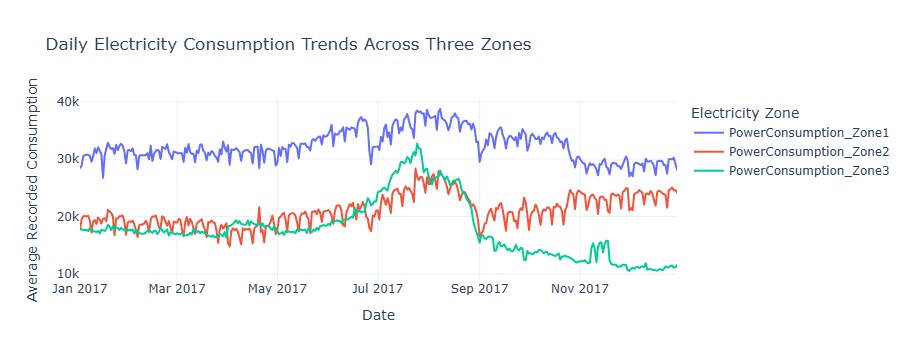

In [62]:

daily_trend_long = daily_trend.melt(
    id_vars='Date',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Recorded Consumption'
)


fig = px.line(
    daily_trend_long,
    x='Date',
    y='Recorded Consumption',
    color='Zone',
    title='Daily Electricity Consumption Trends Across Three Zones',
    labels={
        'Date': 'Date',
        'Recorded Consumption': 'Average Recorded Consumption',
        'Zone': 'Electricity Zone'
    },
    template='plotly_white'
)

fig.update_layout(
    hovermode='x unified',
    legend_title='Electricity Zone',
    xaxis_title='Date',
    yaxis_title='Average Recorded Consumption'
)

fig.show()


### Average Electricity Consumption by Zone

In [63]:

zone_average = (
    df[zone_columns]
    .mean()
    .rename_axis('Zone')
    .reset_index(name='Average Consumption')
    .sort_values('Average Consumption', ascending=False)
)

display(zone_average.round(2))


,Zone,Average Consumption
0,PowerConsumption_Zone1,"32,344.97"
1,PowerConsumption_Zone2,"21,042.51"
2,PowerConsumption_Zone3,"17,835.41"


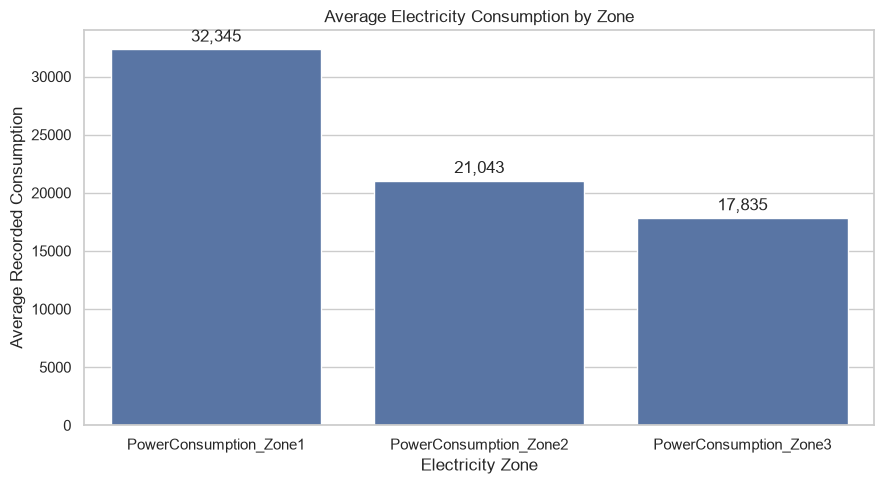

In [64]:

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=zone_average,
    x='Zone',
    y='Average Consumption'
)

ax.set_title('Average Electricity Consumption by Zone')
ax.set_xlabel('Electricity Zone')
ax.set_ylabel('Average Recorded Consumption')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()
plt.show()


### Hourly Electricity Consumption Patterns

In [65]:

hourly_trend = (
    df.groupby('Hour')[zone_columns]
    .mean()
    .reset_index()
)

hourly_trend_long = hourly_trend.melt(
    id_vars='Hour',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

display(hourly_trend.round(2))


,Hour,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,0,"30,217.24","19,692.07","18,657.22"
1,1,"27,565.53","17,765.08","16,970.80"
2,2,"26,292.69","16,730.16","15,981.10"
3,3,"25,338.12","16,052.59","15,238.61"
4,4,"24,633.58","15,624.08","14,671.04"
5,5,"23,437.58","14,974.91","13,226.38"
6,6,"23,203.60","14,934.70","12,051.60"
7,7,"24,038.35","15,719.12","11,667.86"
8,8,"26,583.26","17,529.68","12,793.79"
9,9,"29,725.36","19,640.72","14,478.27"


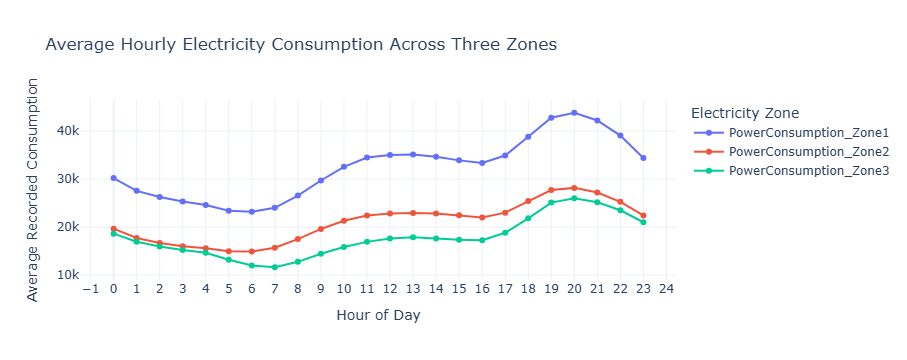

In [66]:

fig = px.line(
    hourly_trend_long,
    x='Hour',
    y='Average Consumption',
    color='Zone',
    markers=True,
    title='Average Hourly Electricity Consumption Across Three Zones',
    labels={
        'Hour': 'Hour of Day',
        'Average Consumption': 'Average Recorded Consumption',
        'Zone': 'Electricity Zone'
    },
    template='plotly_white'
)

fig.update_layout(
    xaxis=dict(
        tickmode='linear',
        dtick=1
    ),
    hover
    mode='x unified',
    legend_title='Electricity Zone'
)

fig.show()


### Monthly Electricity Consumption Patterns

In [67]:

monthly_trend = (
    df.groupby('Month')[zone_columns]
    .mean()
    .reset_index()
)

month_names = {
    1: 'January', 2: 'February', 3: 'March',
    4: 'April', 5: 'May', 6: 'June',
    7: 'July', 8: 'August', 9: 'September',
    10: 'October', 11: 'November', 12: 'December'
}

monthly_trend['Month Name'] = monthly_trend['Month'].map(month_names)

monthly_trend_long = monthly_trend.melt(
    id_vars=['Month', 'Month Name'],
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

display(monthly_trend.round(2))


,Month,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Month Name
0,1,"31,032.49","19,394.44","17,746.10",January
1,2,"30,985.75","18,787.79","17,335.00",February
2,3,"31,155.17","18,457.94","16,947.69",March
3,4,"31,169.77","17,633.97","18,593.17",April
4,5,"32,396.01","19,977.29","17,621.10",May
5,6,"34,605.54","20,670.93","20,430.94",June
6,7,"35,831.55","24,147.89","28,194.11",July
7,8,"36,435.19","24,656.22","24,648.89",August
8,9,"33,396.68","20,180.43","14,922.80",September
9,10,"32,827.66","21,468.99","13,264.10",October


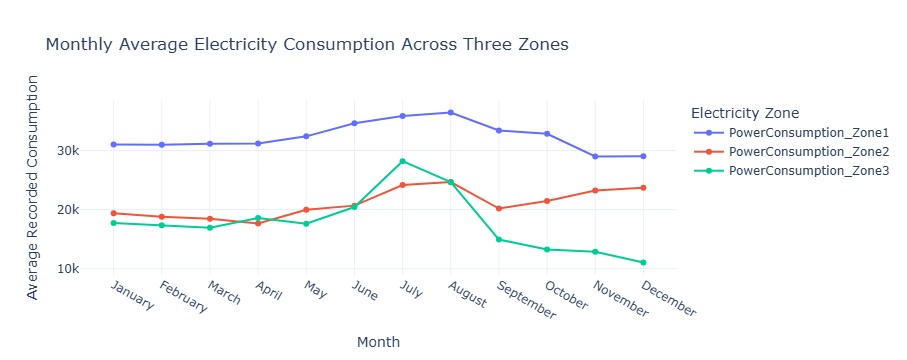

In [68]:

fig = px.line(
    monthly_trend_long,
    x='Month Name',
    y='Average Consumption',
    color='Zone',
    markers=True,
    category_orders={'Month Name': list(month_names.values())},
    title='Monthly Average Electricity Consumption Across Three Zones',
    labels={
        'Month Name': 'Month',
        'Average Consumption': 'Average Recorded Consumption',
        'Zone': 'Electricity Zone'
    },
    template='plotly_white'
)

fig.update_layout(
    hovermode='x unified',
    legend_title='Electricity Zone'
)

fig.show()


### Day-of-Week Consumption Comparison

In [69]:

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_trend = (
    df.groupby('Day')[zone_columns]
    .mean()
    .reindex(weekday_order)
    .reset_index()
    .rename(columns={'Day': 'Weekday'})
)

weekday_trend_long = weekday_trend.melt(
    id_vars='Weekday',
    value_vars=zone_columns,
    var_name='Zone',
    value_name='Average Consumption'
)

display(weekday_trend.round(2))


,Weekday,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,Monday,"32,615.41","21,280.07","17,809.08"
1,Tuesday,"32,713.03","21,518.60","17,831.69"
2,Wednesday,"32,871.76","21,627.36","17,851.40"
3,Thursday,"32,842.48","21,845.16","17,843.69"
4,Friday,"32,339.00","21,461.04","17,545.97"
5,Saturday,"32,253.03","20,585.96","18,011.19"
6,Sunday,"30,780.08","18,979.38","17,954.83"


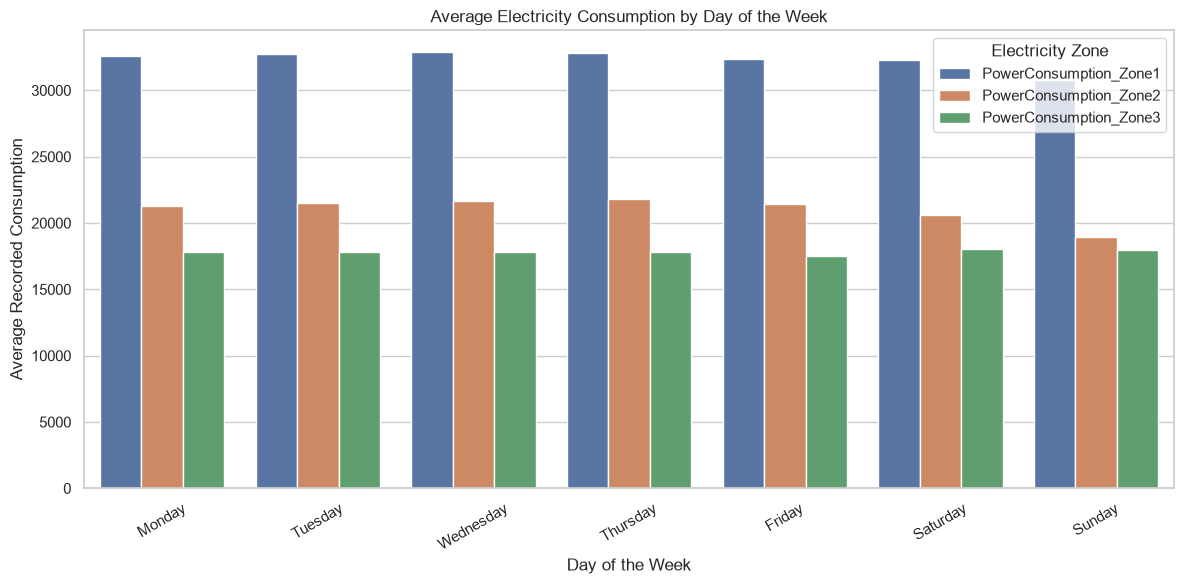

In [70]:

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=weekday_trend_long,
    x='Weekday',
    y='Average Consumption',
    hue='Zone'
)

ax.set_title('Average Electricity Consumption by Day of the Week')
ax.set_xlabel('Day of the Week')
ax.set_ylabel('Average Recorded Consumption')
ax.legend(title='Electricity Zone')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Environmental Factor Relationships

In [71]:

environmental_plot_data = df[
    ['Temperature', 'Humidity', 'WindSpeed'] + zone_columns
].sample(
    n=5000,
    random_state=42
)

display(environmental_plot_data.head())
print("Observations selected:", len(environmental_plot_data))


,Temperature,Humidity,WindSpeed,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
15506,22.76,29.73,0.09,"32,985.15","19,396.74","17,623.27"
51943,15.92,54.44,0.09,"34,737.64","29,803.01","14,417.29"
212,15.08,57.23,0.08,"27,894.68","20,808.51","16,458.80"
11210,12.42,72.30,0.08,"42,476.94","23,634.15","25,089.68"
16307,14.58,80.60,0.08,"21,341.14","12,006.11","11,531.64"


Observations selected: 5000


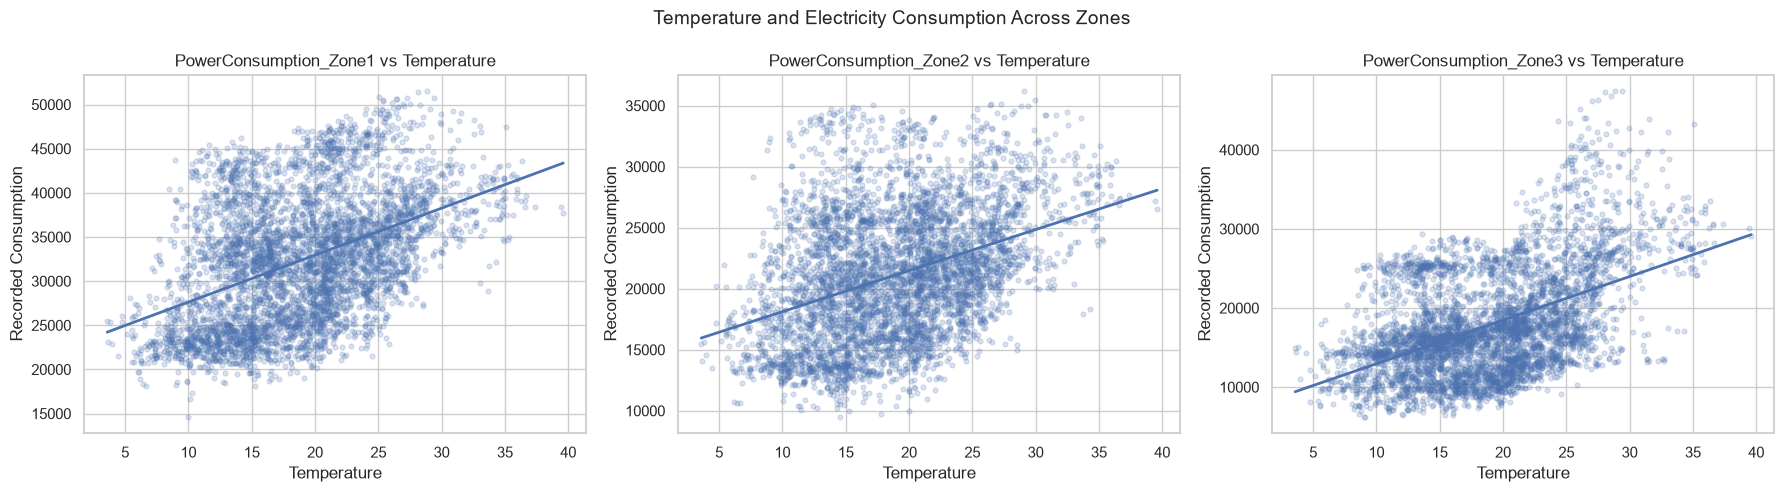

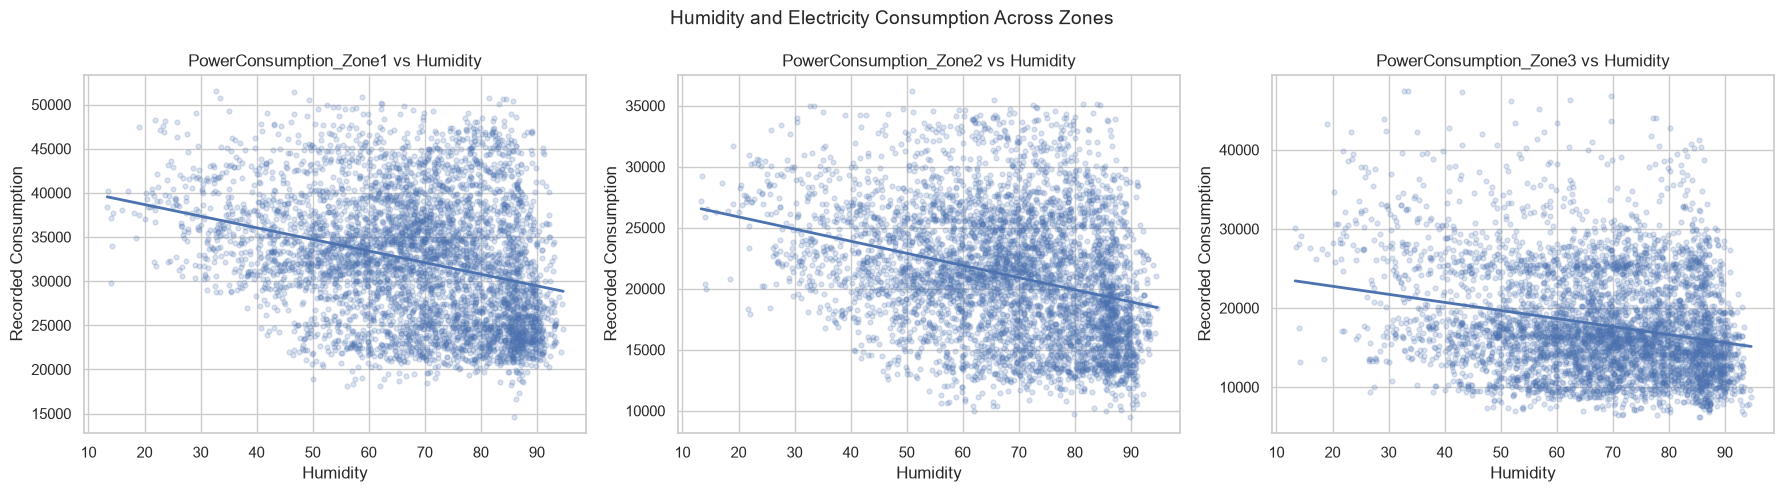

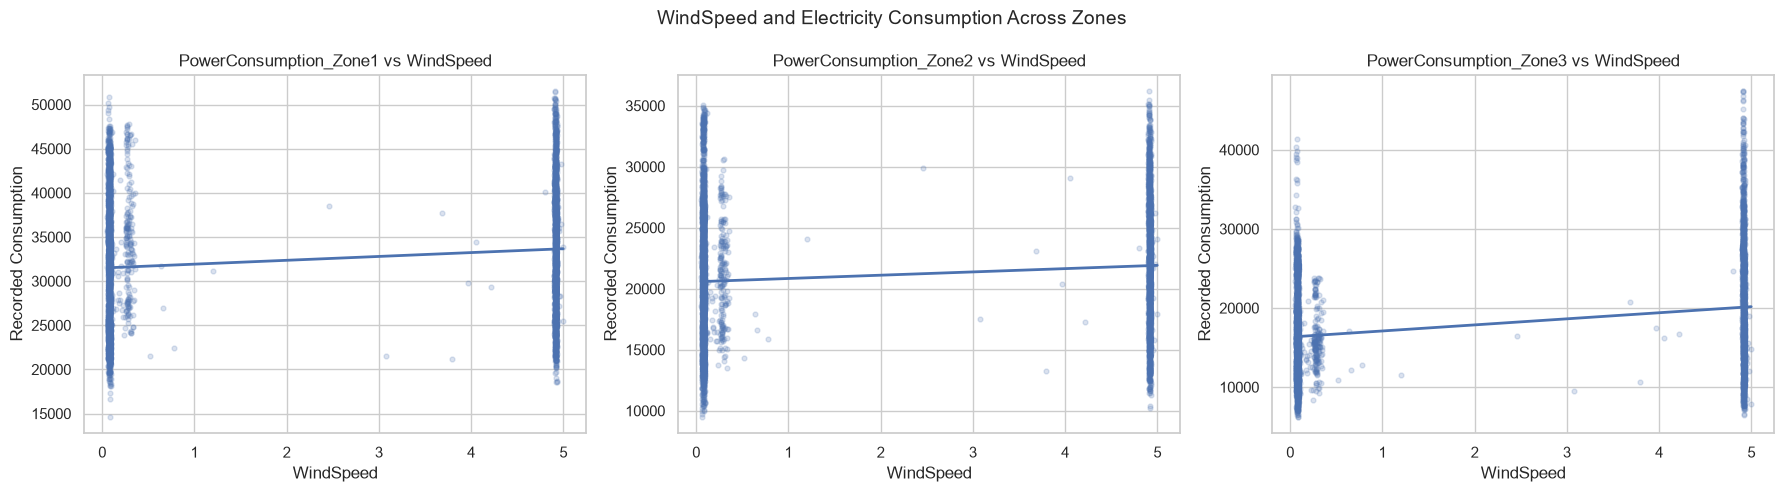

In [72]:

environmental_variables = ['Temperature', 'Humidity', 'WindSpeed']

for factor in environmental_variables:

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, zone in zip(axes, zone_columns):
        sns.regplot(
            data=environmental_plot_data,
            x=factor,
            y=zone,
            ax=ax,
            scatter_kws={'alpha': 0.2, 's': 12},
            line_kws={'linewidth': 2},
            ci=None
        )

        ax.set_title(f'{zone} vs {factor}')
        ax.set_xlabel(factor)
        ax.set_ylabel('Recorded Consumption')

    fig.suptitle(
        f'{factor} and Electricity Consumption Across Zones',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


### Three-Zone Consumption Comparison

In [73]:

zone_distribution = df[zone_columns].melt(
    var_name='Zone',
    value_name='Recorded Consumption'
)

display(zone_distribution.groupby('Zone')['Recorded Consumption'].describe().round(2))


,count,mean,std,min,25%,50%,75%,max
Zone,,,,,,,,
PowerConsumption_Zone1,"52,416.00","32,344.97","7,130.56","13,895.70","26,310.67","32,265.92","37,309.02","52,204.40"
PowerConsumption_Zone2,"52,416.00","21,042.51","5,201.47","8,560.08","16,980.77","20,823.17","24,713.72","37,408.86"
PowerConsumption_Zone3,"52,416.00","17,835.41","6,622.17","5,935.17","13,129.33","16,415.12","21,624.10","47,598.33"


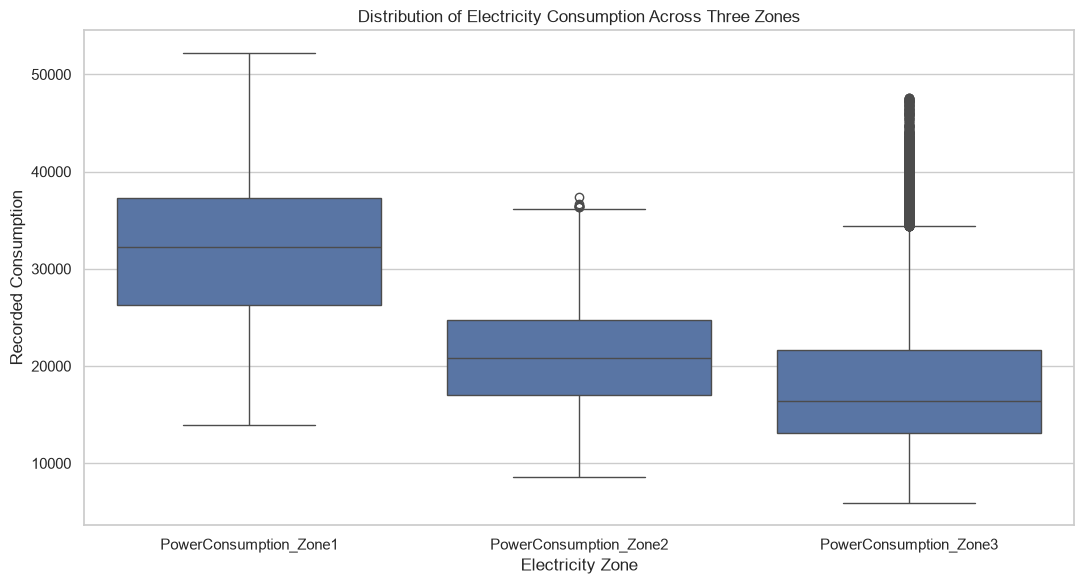

In [74]:

plt.figure(figsize=(11, 6))

ax = sns.boxplot(
    data=zone_distribution,
    x='Zone',
    y='Recorded Consumption'
)

ax.set_title('Distribution of Electricity Consumption Across Three Zones')
ax.set_xlabel('Electricity Zone')
ax.set_ylabel('Recorded Consumption')

plt.tight_layout()
plt.show()


### Environmental Correlation Heatmap

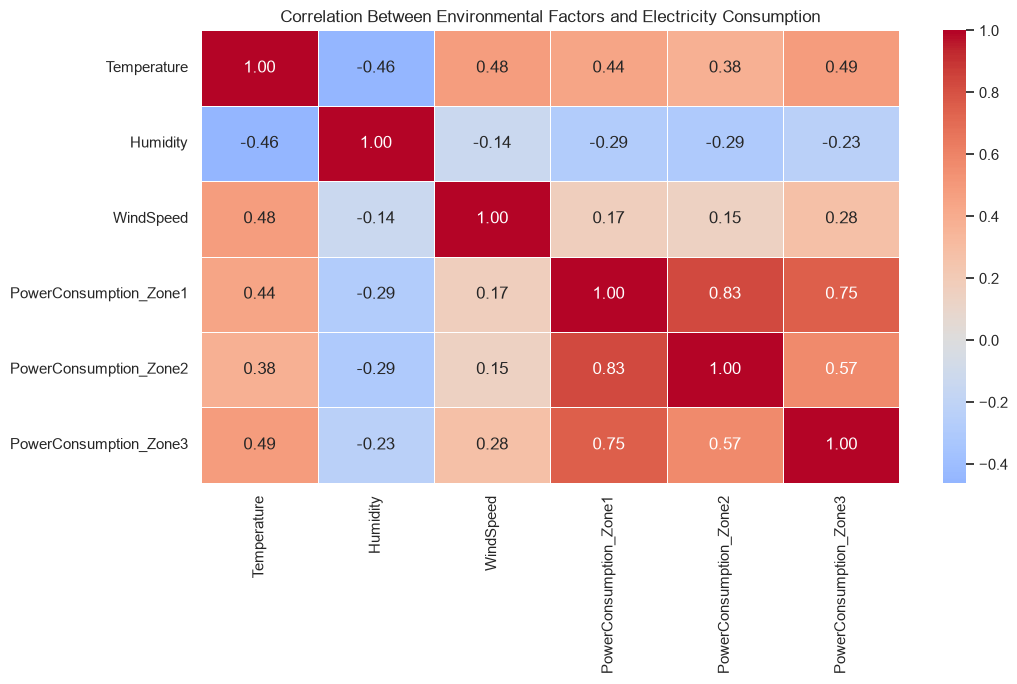

In [75]:

correlation_variables = [
    'Temperature', 'Humidity', 'WindSpeed'
] + zone_columns

correlation_matrix = df[correlation_variables].corr()

plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Environmental Factors and Electricity Consumption')
plt.tight_layout()
plt.show()



# Business Insights and Recommendations

## Objective

Translate the analytical findings into meaningful business insights and actionable recommendations for an energy management organisation.

The objective is to explain what the observed consumption patterns mean for energy management, identify areas requiring operational attention, and recommend evidence-based actions to improve demand monitoring and planning.

## Key Business Findings

### Zone 1 Has the Highest Average Electricity Consumption

Zone 1 records the highest average consumption at **32,344.97**, compared with 21,042.51 in Zone 2 and 17,835.41 in Zone 3.

Zone 1's average consumption is approximately 81.4% higher than Zone 3's.

**Business implication:**

Zone 1 represents the largest consumption requirement among the three zones. Energy managers should give particular attention to its demand profile when planning supply capacity, monitoring consumption and allocating operational resources.

### All Three Zones Experience Peak Consumption at 20:00

All three zones record their highest average hourly consumption at 20:00.

| Zone | Average Consumption at 20:00 |
|---|---:|
| Zone 1 | 43,822.59 |
| Zone 2 | 28,186.91 |
| Zone 3 | 26,027.61 |

Consumption reaches its lowest average levels during the early morning, around 06:00–07:00.

**Business implication:**

The common evening peak represents an important period for demand monitoring and operational planning. Energy managers should consider the 18:00–21:00 period when assessing peak-demand requirements and preparing operational schedules.

### Electricity Consumption Varies Across Months

Monthly analysis reveals different consumption patterns across the three zones.

- Zone 1 records its highest monthly average in August at 36,435.19.
- Zone 2 also peaks in August at 24,656.22.
- Zone 3 peaks in July at 28,194.11.
- Zone 3 experiences a substantial increase during July and August, followed by a decline from September.

**Business implication:**

Demand planning based on annual averages may overlook seasonal variations. Historical monthly profiles can help energy managers anticipate periods of increased demand and prepare operational resources accordingly.

### Weekday and Weekend Consumption Patterns Differ Across Zones

The highest and lowest average consumption days differ across the three zones.

| Zone | Highest Consumption Day | Average | Lowest Consumption Day | Average |
|---|---|---:|---|---:|
| Zone 1 | Wednesday | 32,871.76 | Sunday | 30,780.08 |
| Zone 2 | Thursday | 21,845.16 | Sunday | 18,979.38 |
| Zone 3 | Saturday | 18,011.19 | Friday | 17,545.97 |

Zone 1 and Zone 2 record their lowest average consumption on Sunday, while Zone 3 records its highest average on Saturday.

**Business implication:**

The differences indicate that the three zones do not follow identical weekly demand patterns. Zone-specific monitoring and planning may therefore be more appropriate than applying the same operating assumptions across all zones.

### Temperature Has a Positive Association with Electricity Consumption

Pearson correlation analysis indicates a moderate positive relationship between temperature and electricity consumption across all three zones.

| Zone | Temperature Correlation |
|---|---:|
| Zone 1 | 0.44 |
| Zone 2 | 0.38 |
| Zone 3 | 0.49 |

Zone 3 records the strongest positive correlation.

Consumption also generally increases across higher temperature ranges.

**Business implication:**

Temperature may provide useful additional information for electricity demand monitoring and future forecasting models. However, the observed association does not establish that temperature causes increased electricity consumption.

### Humidity Has a Negative Association with Electricity Consumption

Pearson correlation analysis indicates a negative relationship between humidity and electricity consumption.

| Zone | Humidity Correlation |
|---|---:|
| Zone 1 | -0.29 |
| Zone 2 | -0.29 |
| Zone 3 | -0.23 |

The consumption profiles across humidity ranges also generally show lower average consumption at higher humidity levels.

**Business implication:**

Humidity may provide additional context when investigating changes in electricity consumption. It should be considered alongside other environmental and operational variables rather than used independently for demand forecasting.

### Zone 3 Has the Greatest Relative Consumption Variability

The coefficient of variation indicates that Zone 3 has the highest relative variability.

| Zone | Mean Consumption | Standard Deviation | Coefficient of Variation |
|---|---:|---:|---:|
| Zone 1 | 32,344.97 | 7,130.56 | 22.05% |
| Zone 2 | 21,042.51 | 5,201.47 | 24.72% |
| Zone 3 | 17,835.41 | 6,622.17 | 37.13% |

Zone 3 also records a maximum consumption value of 47,598.33 despite having the lowest average consumption.

**Business implication:**

Average consumption alone does not adequately describe demand behaviour. Zone 3 requires closer monitoring of fluctuations and unusually high readings to support more effective demand management.

### Wind Speed Has a Weak and Inconsistent Relationship with Electricity Consumption

Pearson correlation coefficients indicate weak positive relationships between wind speed and consumption.

| Zone | Pearson Correlation | Spearman Correlation |
|---|---:|---:|
| Zone 1 | 0.17 | 0.11 |
| Zone 2 | 0.15 | 0.09 |
| Zone 3 | 0.28 | 0.08 |

The weaker Spearman correlations suggest that the observed Pearson relationships may be influenced by the distribution of wind speed or extreme observations.

**Business implication:**

Wind speed does not currently demonstrate a sufficiently consistent relationship to justify relying on it as a major demand-planning indicator. Further investigation would be required before including it as a significant forecasting variable.

## Actionable Business Recommendations

### Strengthen Peak-Demand Management

**Proposed action:**

Establish closer monitoring of electricity consumption during the evening peak period, particularly between 18:00 and 21:00.

**Expected management benefit:**

Improved visibility of peak-demand periods and better preparation for periods of increased consumption.

**Performance measures:**
- Peak-period average consumption by zone.
- Maximum recorded consumption by zone.
- Changes in evening demand over time.

### Introduce Zone-Specific Demand Monitoring

**Proposed action:**

Develop separate monitoring profiles for Zones 1, 2 and 3.

Prioritise:
- Zone 1 for its high average consumption.
- Zone 3 for its greater relative variability.
- Zone 2 for monitoring changes in its consumption profile.

**Expected management benefit:**

Improved visibility of differences between zones and more targeted operational planning.

**Performance measures:**
- Monthly average consumption by zone.
- Coefficient of variation by zone.
- Maximum and minimum consumption readings.
- Monthly changes in consumption.

### Incorporate Seasonal Patterns into Demand Planning

**Proposed action:**

Use historical monthly consumption patterns to prepare for periods of increased demand, particularly July and August.

**Expected management benefit:**

Better anticipation of seasonal demand changes and improved operational preparedness.

**Performance measures:**
- Monthly forecast versus actual consumption.
- Month-on-month consumption changes.
- Forecast error by zone.

### Develop an Environmental Demand-Monitoring Model

**Proposed action:**

Investigate temperature and humidity as potential explanatory variables in a future electricity demand forecasting model.

Temperature should receive particular attention because it demonstrates a moderate positive association across all three zones.

**Expected management benefit:**

A better understanding of how environmental conditions relate to electricity consumption and whether they improve demand forecasting.

**Performance measures:**
- Mean Absolute Error (MAE).
- Root Mean Squared Error (RMSE).
- Forecast performance against a baseline model.
- Forecast performance by zone.

### Establish a Regular Management Reporting Process

**Proposed action:**

Introduce a recurring electricity consumption report covering:

- Overall consumption trends.
- Zone-level consumption comparisons.
- Peak and low-demand periods.
- Monthly and weekly consumption patterns.
- Environmental relationships.
- Significant changes and unusual consumption readings.

**Expected management benefit:**

More consistent monitoring, improved management visibility and earlier identification of changes in demand.

**Performance measures:**
- Reporting frequency.
- Data completeness.
- Number of significant demand deviations identified.
- Timeliness of reporting.

## Overall Business Implications

The analysis provides an evidence base for improving electricity demand monitoring and operational planning.

The main management priorities are:

- **Peak-demand management:** Monitor the common evening peak across all three zones.
- **Zone-specific planning:** Account for differences in consumption magnitude and variability.
- **Seasonal demand planning:** Incorporate historical monthly consumption patterns into operational preparation.
- **Environmental monitoring:** Investigate temperature and humidity as potential inputs to future demand forecasting.
- **Management reporting:** Establish regular zone-level reporting to identify demand changes and support operational decisions.

These priorities can help an energy management organisation move from general consumption monitoring towards more structured, evidence-based demand management.

## Analytical Limitations

The following limitations should be considered when interpreting the findings and applying the recommendations:

- **Historical coverage:** The dataset covers 2017 only. The observed patterns should not automatically be assumed to represent current electricity demand.
- **Incomplete calendar coverage:** The dataset ends on 30 December 2017 and does not include 31 December.
- **Measurement units:** The original data dictionary labels consumption values in kWh, but the precise interpretation of each 10-minute observation requires verification.
- **Correlation versus causation:** The observed environmental relationships do not establish causal effects on electricity consumption.
- **Limited explanatory variables:** The dataset does not include electricity prices, customer numbers, generation capacity, outages or other operational factors that may influence demand.
- **No validated forecasting model:** The analysis is descriptive and exploratory. Predictive performance has not been established.

Consequently, the findings should be treated as historical analytical evidence rather than definitive predictions of current or future demand.

## Conclusion

The analysis identified meaningful differences in electricity consumption across the three zones, including variations in average demand, hourly patterns, monthly trends and environmental relationships.

Zone 1 recorded the highest average consumption, while Zone 3 demonstrated the greatest relative variability. All three zones experienced their highest average consumption at approximately 20:00, highlighting the importance of evening peak-demand monitoring. Monthly analysis also revealed increased consumption during July and August, although the timing and magnitude differed across zones.

Temperature showed a moderate positive association with electricity consumption, while humidity showed a negative association. Wind speed demonstrated a weaker and less consistent relationship.

Based on these findings, the organisation should strengthen peak-demand monitoring, adopt zone-specific demand management, incorporate seasonal patterns into operational planning and investigate environmental variables for future forecasting applications.

Overall, the findings provide a descriptive evidence base for improving electricity demand monitoring, operational planning and management reporting. Further analysis using more recent data and additional operational variables would be required before developing reliable predictive models.
